# Data Quality Analysis: OpenAQ PM2.5 & Open-Meteo (Hanoi & Ho Chi Minh City)

- **Objective:** Evaluate station coverage, outage gaps, API rate limits, and schema compliance (`docs/CONTRACTS.md`) of air quality and meteorological data in Hanoi & Ho Chi Minh City to determine suitability for the **Live Demo** versus **Offline Drift Experiments**.
- **Verified API Rate Limits:**
  - **OpenAQ API v3 (`GET /v3/locations`, `/v3/sensors/{id}/hours`):** `60 requests/minute` (`x-ratelimit-limit: 60`, `x-ratelimit-reset: 60s`, up to `1,000` records/page). Polling 5 stations hourly in the Live Demo uses only `5 requests/hour` (`< 10%` of the per-minute quota).
  - **Open-Meteo API (`GET /v1/archive`, `/v1/forecast`):** Free tier (no API key), supports `wind_speed_unit=ms` and `UTC` timestamps, returning full 2-year hourly series (`17,520 hours/station`) in a single request.
- **Repository Dataset (`data/sample/`):** 1-week hourly sample (`2025-11-15T00:00:00Z` → `2025-11-21T23:00:00Z`, `168 hours/station`) for the 5 usable stations, extracted from the 2-year assessment across all 62 stations (`2024-11-14` → `2026-11-14`, `17,520 hours`).

## 1. 62-Station Survey & 2-Year Completeness Summary (`2024-11-14` → `2026-11-14`)

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.titleweight"] = "bold"

CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
SAMPLE_DIR = PROJECT_ROOT / "data" / "sample"
TOTAL_WINDOW_HOURS = 17520

# Lifecycle breakdown of all 62 surveyed stations over [2024-11-14T00:00:00Z, 2026-11-14T00:00:00Z)
df_lifecycle = pd.DataFrame(
    [
        {
            "status_in_2yr_window": "1. Stopped before 2024-11-14 (0 records)",
            "HCMC": 4,
            "Hanoi": 22,
            "Total": 26,
        },
        {
            "status_in_2yr_window": "2. Has records but 100% NaN (US Post HCMC - 7440)",
            "HCMC": 1,
            "Hanoi": 0,
            "Total": 1,
        },
        {
            "status_in_2yr_window": "3. Has valid data but stopped before 2026-11",
            "HCMC": 13,
            "Hanoi": 16,
            "Total": 29,
        },
        {
            "status_in_2yr_window": "4. Active through 2026-11 (5 selected for Demo)",
            "HCMC": 1,
            "Hanoi": 5,
            "Total": 6,
        },
    ]
)
display(df_lifecycle)

# 2-year metrics for the 5 usable stations and 3 representative inactive/excluded stations
df_2yr_summary = pd.DataFrame(
    [
        {
            "city": "HCMC",
            "station_id": 3276359,
            "sensor_id": 11357424,
            "station_name": "CMT8",
            "is_monitor": False,
            "usable_demo": True,
            "valid_hours": 16048,
            "completeness_2yr_pct": 91.60,
            "missing_2yr_pct": 8.40,
            "active_span_h": 17390,
            "missing_in_active_pct": 7.72,
            "num_gaps": 62,
            "num_gaps_ge_24h": 5,
            "max_gap_hours": 690,
            "first_valid_utc": "2024-11-19 10:00",
            "last_valid_utc": "2026-11-13 23:00",
        },
        {
            "city": "Hanoi",
            "station_id": 4946812,
            "sensor_id": 13502151,
            "station_name": "CV Nhân Chính - Khuất Duy Tiến",
            "is_monitor": True,
            "usable_demo": True,
            "valid_hours": 11531,
            "completeness_2yr_pct": 65.82,
            "missing_2yr_pct": 34.18,
            "active_span_h": 11961,
            "missing_in_active_pct": 3.60,
            "num_gaps": 63,
            "num_gaps_ge_24h": 4,
            "max_gap_hours": 86,
            "first_valid_utc": "2025-07-03 15:00",
            "last_valid_utc": "2026-11-13 23:00",
        },
        {
            "city": "Hanoi",
            "station_id": 2161292,
            "sensor_id": 7772032,
            "station_name": "Số 46, phố Lưu Quang Vũ",
            "is_monitor": True,
            "usable_demo": True,
            "valid_hours": 11392,
            "completeness_2yr_pct": 65.02,
            "missing_2yr_pct": 34.98,
            "active_span_h": 17498,
            "missing_in_active_pct": 34.90,
            "num_gaps": 228,
            "num_gaps_ge_24h": 61,
            "max_gap_hours": 859,
            "first_valid_utc": "2024-11-14 00:00",
            "last_valid_utc": "2026-11-13 01:00",
        },
        {
            "city": "Hanoi",
            "station_id": 4946813,
            "sensor_id": 13502154,
            "station_name": "Số 1 Giải Phóng - Bạch Mai",
            "is_monitor": True,
            "usable_demo": True,
            "valid_hours": 11098,
            "completeness_2yr_pct": 63.34,
            "missing_2yr_pct": 36.66,
            "active_span_h": 11961,
            "missing_in_active_pct": 7.22,
            "num_gaps": 189,
            "num_gaps_ge_24h": 8,
            "max_gap_hours": 136,
            "first_valid_utc": "2025-07-03 15:00",
            "last_valid_utc": "2026-11-13 23:00",
        },
        {
            "city": "Hanoi",
            "station_id": 6123215,
            "sensor_id": 14581375,
            "station_name": "Dragon",
            "is_monitor": False,
            "usable_demo": True,
            "valid_hours": 8646,
            "completeness_2yr_pct": 49.35,
            "missing_2yr_pct": 50.65,
            "active_span_h": 8899,
            "missing_in_active_pct": 2.84,
            "num_gaps": 42,
            "num_gaps_ge_24h": 2,
            "max_gap_hours": 119,
            "first_valid_utc": "2025-11-08 05:00",
            "last_valid_utc": "2026-11-13 23:00",
        },
        {
            "city": "Hanoi",
            "station_id": 4946811,
            "sensor_id": 13502150,
            "station_name": "556 Nguyễn Văn Cừ (Stopped 07/2026)",
            "is_monitor": True,
            "usable_demo": False,
            "valid_hours": 7829,
            "completeness_2yr_pct": 44.69,
            "missing_2yr_pct": 55.31,
            "active_span_h": 9044,
            "missing_in_active_pct": 13.43,
            "num_gaps": 134,
            "num_gaps_ge_24h": 8,
            "max_gap_hours": 625,
            "first_valid_utc": "2025-07-03 15:00",
            "last_valid_utc": "2026-07-15 10:00",
        },
        {
            "city": "Hanoi",
            "station_id": 2161306,
            "sensor_id": 7772087,
            "station_name": "Minh Khai (Excluded - 160d Gap, 13 pts >500)",
            "is_monitor": True,
            "usable_demo": False,
            "valid_hours": 4292,
            "completeness_2yr_pct": 24.50,
            "missing_2yr_pct": 75.50,
            "active_span_h": 17497,
            "missing_in_active_pct": 75.47,
            "num_gaps": 271,
            "num_gaps_ge_24h": 28,
            "max_gap_hours": 3849,
            "first_valid_utc": "2024-11-14 01:00",
            "last_valid_utc": "2026-11-13 01:00",
        },
        {
            "city": "Hanoi",
            "station_id": 7441,
            "sensor_id": 21632,
            "station_name": "US Diplomatic Post HN (Stopped 04/2025)",
            "is_monitor": True,
            "usable_demo": False,
            "valid_hours": 2905,
            "completeness_2yr_pct": 16.58,
            "missing_2yr_pct": 83.42,
            "active_span_h": 3519,
            "missing_in_active_pct": 17.45,
            "num_gaps": 25,
            "num_gaps_ge_24h": 1,
            "max_gap_hours": 556,
            "first_valid_utc": "2024-11-14 00:00",
            "last_valid_utc": "2025-04-09 14:00",
        },
    ]
)
display(df_2yr_summary)

,status_in_2yr_window,HCMC,Hanoi,Total
0,1. Stopped before 2024-11-14 (0 records),4,22,26
1,2. Has records but 100% NaN (US Post HCMC - 7440),1,0,1
2,3. Has valid data but stopped before 2026-11,13,16,29
3,4. Active through 2026-11 (5 selected for Demo),1,5,6


,city,station_id,sensor_id,station_name,is_monitor,usable_demo,valid_hours,completeness_2yr_pct,missing_2yr_pct,active_span_h,missing_in_active_pct,num_gaps,num_gaps_ge_24h,max_gap_hours,first_valid_utc,last_valid_utc
0,HCMC,3276359,11357424,CMT8,False,True,16048,91.60,8.40,17390,7.72,62,5,690,2024-11-19 10:00,2026-11-13 23:00
1,Hanoi,4946812,13502151,CV Nhân Chính - Khuất Duy Tiến,True,True,11531,65.82,34.18,11961,3.60,63,4,86,2025-07-03 15:00,2026-11-13 23:00
2,Hanoi,2161292,7772032,"Số 46, phố Lưu Quang Vũ",True,True,11392,65.02,34.98,17498,34.90,228,61,859,2024-11-14 00:00,2026-11-13 01:00
3,Hanoi,4946813,13502154,Số 1 Giải Phóng - Bạch Mai,True,True,11098,63.34,36.66,11961,7.22,189,8,136,2025-07-03 15:00,2026-11-13 23:00
4,Hanoi,6123215,14581375,Dragon,False,True,8646,49.35,50.65,8899,2.84,42,2,119,2025-11-08 05:00,2026-11-13 23:00
5,Hanoi,4946811,13502150,556 Nguyễn Văn Cừ (Stopped 07/2026),True,False,7829,44.69,55.31,9044,13.43,134,8,625,2025-07-03 15:00,2026-07-15 10:00
6,Hanoi,2161306,7772087,"Minh Khai (Excluded - 160d Gap, 13 pts >500)",True,False,4292,24.50,75.50,17497,75.47,271,28,3849,2024-11-14 01:00,2026-11-13 01:00
7,Hanoi,7441,21632,US Diplomatic Post HN (Stopped 04/2025),True,False,2905,16.58,83.42,3519,17.45,25,1,556,2024-11-14 00:00,2025-04-09 14:00


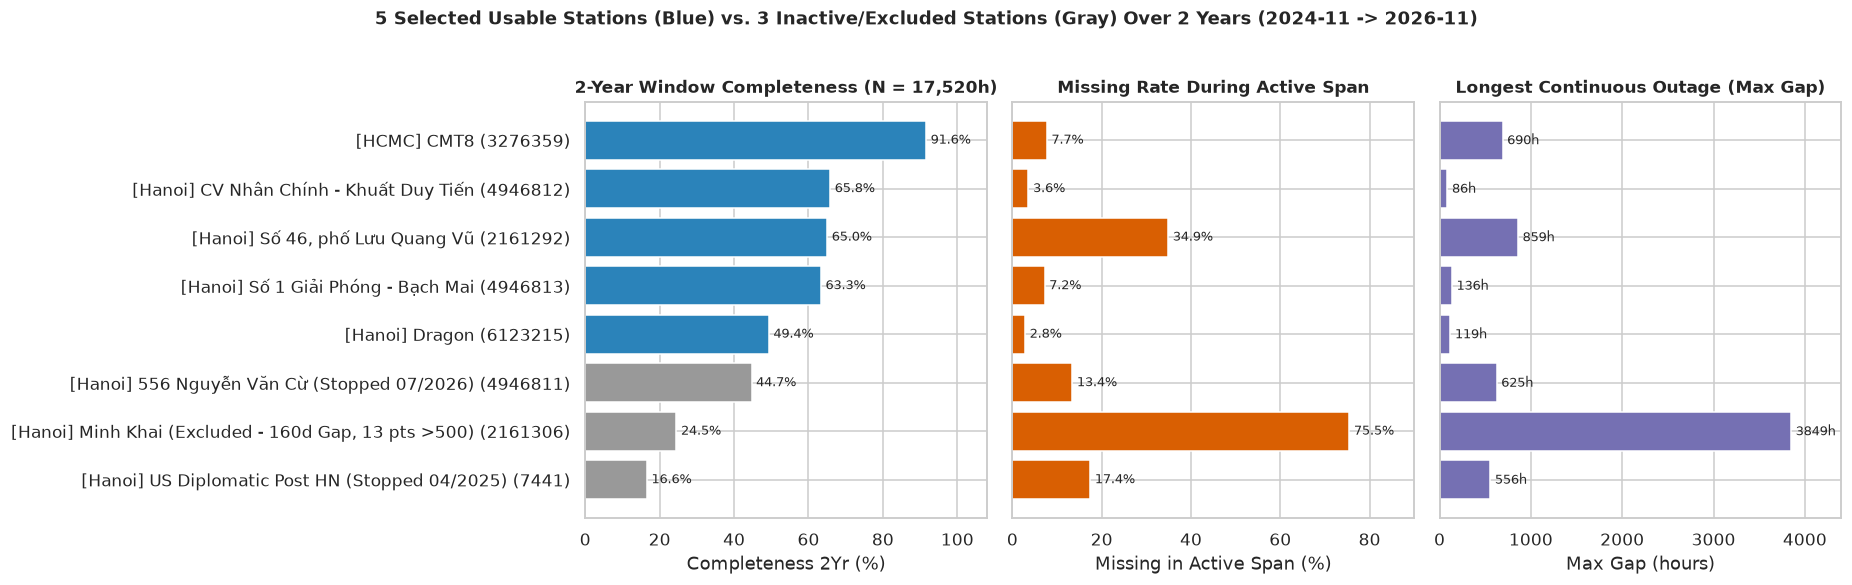

In [2]:
# Figure 1: 2-Year Completeness vs. Missing Rate in Active Span & Max Outage Gap
df_plot = df_2yr_summary.sort_values("valid_hours", ascending=True).copy()
df_plot["label"] = (
    "["
    + df_plot["city"]
    + "] "
    + df_plot["station_name"]
    + " ("
    + df_plot["station_id"].astype(str)
    + ")"
)
bar_colors = ["#2b83ba" if u else "#999999" for u in df_plot["usable_demo"]]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2), sharey=True)

b0 = axes[0].barh(df_plot["label"], df_plot["completeness_2yr_pct"], color=bar_colors)
axes[0].set_title("2-Year Window Completeness (N = 17,520h)")
axes[0].set_xlabel("Completeness 2Yr (%)")
axes[0].set_xlim(0, 108)
axes[0].bar_label(b0, fmt="%.1f%%", padding=3, fontsize=8.5)

b1 = axes[1].barh(df_plot["label"], df_plot["missing_in_active_pct"], color="#d95f02")
axes[1].set_title("Missing Rate During Active Span")
axes[1].set_xlabel("Missing in Active Span (%)")
axes[1].set_xlim(0, 90)
axes[1].bar_label(b1, fmt="%.1f%%", padding=3, fontsize=8.5)

b2 = axes[2].barh(df_plot["label"], df_plot["max_gap_hours"], color="#7570b3")
axes[2].set_title("Longest Continuous Outage (Max Gap)")
axes[2].set_xlabel("Max Gap (hours)")
axes[2].set_xlim(0, 4400)
axes[2].bar_label(b2, fmt="%dh", padding=3, fontsize=8.5)

plt.suptitle(
    "5 Selected Usable Stations (Blue) vs. 3 Inactive/Excluded Stations (Gray) Over 2 Years (2024-11 -> 2026-11)",
    fontsize=12,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

**Key Findings:**
- Out of 62 surveyed stations, **5 usable stations remain active through `2026-11`**: `3276359 (CMT8 - HCMC)` and 4 stations in Hanoi (`4946812`, `2161292`, `4946813`, `6123215`).
- Recently deployed Hanoi stations (`4946812`, `4946813`, `6123215`) and `CMT8` exhibit very low missing rates during their active spans (`2.84%–7.72%`), making them well-suited for the **Live Demo**. However, because 2-year Hanoi series are either shorter than 2 years or fragmented by `61` outages `>= 24h` (`2161292`, max gap `859h`), **Offline Drift** experiments will use the **Beijing Multi-Site Air-Quality** benchmark.

---

## 2. 1-Week Sample Dataset Verification (`data/sample/`) Against `docs/CONTRACTS.md`

In [3]:
df_pm25 = pd.read_csv(SAMPLE_DIR / "openaq_pm25_hanoi_hcmc.csv")
df_wx = pd.read_csv(SAMPLE_DIR / "openmeteo_weather_hanoi_hcmc.csv")

for df_tmp in [df_pm25, df_wx]:
    df_tmp["station_name"] = df_tmp["station_name"].astype(str).str.strip()
    df_tmp["event_time_dt"] = pd.to_datetime(df_tmp["event_time"], utc=True)

SAMPLE_START = pd.Timestamp("2025-11-15T00:00:00Z")
SAMPLE_END = pd.Timestamp("2025-11-22T00:00:00Z")
EXPECTED_SAMPLE_HOURS = 168
full_sample_index = pd.date_range(
    start=SAMPLE_START, end=SAMPLE_END - pd.Timedelta(hours=1), freq="1h", tz="UTC"
)

# 2.1. Schema, Duplicate Keys, Value Bounds, and Weather Left-Join Match Rate
df_merged = pd.merge(
    df_pm25,
    df_wx[
        [
            "station_id",
            "event_time",
            "temperature_c",
            "relative_humidity_pct",
            "wind_speed_m_s",
            "wind_direction_deg",
            "precipitation_mm",
        ]
    ],
    on=["station_id", "event_time"],
    how="left",
)

df_schema_audit = pd.DataFrame(
    [
        {
            "dataset": "openaq_pm25_hanoi_hcmc.csv",
            "rows": len(df_pm25),
            "stations": df_pm25["station_id"].nunique(),
            "min_utc": df_pm25["event_time_dt"].min().strftime("%Y-%m-%d %H:%M"),
            "max_utc": df_pm25["event_time_dt"].max().strftime("%Y-%m-%d %H:%M"),
            "dup_(station_id,event_time)": int(
                df_pm25.duplicated(subset=["station_id", "event_time"]).sum()
            ),
            "nan_count": int(df_pm25["pm25_ug_m3"].isna().sum()),
            "neg_count": int((df_pm25["pm25_ug_m3"] < 0).sum()),
            "weather_join_match_pct": round(df_merged["temperature_c"].notna().mean() * 100, 2),
        },
        {
            "dataset": "openmeteo_weather_hanoi_hcmc.csv",
            "rows": len(df_wx),
            "stations": df_wx["station_id"].nunique(),
            "min_utc": df_wx["event_time_dt"].min().strftime("%Y-%m-%d %H:%M"),
            "max_utc": df_wx["event_time_dt"].max().strftime("%Y-%m-%d %H:%M"),
            "dup_(station_id,event_time)": int(
                df_wx.duplicated(subset=["station_id", "event_time"]).sum()
            ),
            "nan_count": int(
                df_wx[
                    [
                        "temperature_c",
                        "relative_humidity_pct",
                        "wind_speed_m_s",
                        "wind_direction_deg",
                        "precipitation_mm",
                    ]
                ]
                .isna()
                .sum()
                .sum()
            ),
            "neg_count": int((df_wx["wind_speed_m_s"] < 0).sum()),
            "weather_join_match_pct": 100.0,
        },
    ]
)
display(df_schema_audit)

# 2.2. Per-Station Summary Over the 1-Week Sample Window (168 expected hours/station)
sample_station_rows = []
for (city, st_id, st_name), grp in df_merged.groupby(
    ["city", "station_id", "station_name"], sort=False
):
    wx_grp = df_wx[df_wx["station_id"] == st_id]
    missing_hours = EXPECTED_SAMPLE_HOURS - len(grp)
    sample_station_rows.append(
        {
            "city": city,
            "station_id": int(st_id),
            "station_name": st_name,
            "pm25_valid_h": len(grp),
            "pm25_missing_h": missing_hours,
            "pm25_completeness_pct": round(len(grp) / EXPECTED_SAMPLE_HOURS * 100, 2),
            "wx_valid_h": len(wx_grp),
            "pm25_mean": round(grp["pm25_ug_m3"].mean(), 2),
            "pm25_median": round(grp["pm25_ug_m3"].median(), 2),
            "pm25_max": round(grp["pm25_ug_m3"].max(), 2),
            "temp_mean_c": round(wx_grp["temperature_c"].mean(), 2),
            "rh_mean_pct": round(wx_grp["relative_humidity_pct"].mean(), 2),
            "wind_mean_m_s": round(wx_grp["wind_speed_m_s"].mean(), 2),
        }
    )
display(pd.DataFrame(sample_station_rows))

,dataset,rows,stations,min_utc,max_utc,"dup_(station_id,event_time)",nan_count,neg_count,weather_join_match_pct
0,openaq_pm25_hanoi_hcmc.csv,815,5,2025-11-15 00:00,2025-11-21 23:00,0,0,0,100.0
1,openmeteo_weather_hanoi_hcmc.csv,840,5,2025-11-15 00:00,2025-11-21 23:00,0,0,0,100.0


,city,station_id,station_name,pm25_valid_h,pm25_missing_h,pm25_completeness_pct,wx_valid_h,pm25_mean,pm25_median,pm25_max,temp_mean_c,rh_mean_pct,wind_mean_m_s
0,HCMC,3276359,CMT8,164,4,97.62,168,35.05,31.25,136.0,25.67,85.13,1.80
1,Hanoi,2161292,"Số 46, phố Lưu Quang Vũ",157,11,93.45,168,32.01,28.50,79.8,19.01,76.70,2.66
2,Hanoi,4946812,Công viên Nhân Chính - Khuất Duy Tiến,168,0,100.00,168,40.55,37.05,94.2,19.01,76.70,2.66
3,Hanoi,4946813,Số 1 đường Giải Phóng - phường Bạch Mai - ĐHBK,162,6,96.43,168,48.85,43.70,121.0,19.01,75.90,2.86
4,Hanoi,6123215,Dragon,164,4,97.62,168,50.75,45.30,170.0,19.05,73.42,3.03


---

## 3. Hourly PM2.5 Time Series & Meteorological Correlation (`data/sample/`)

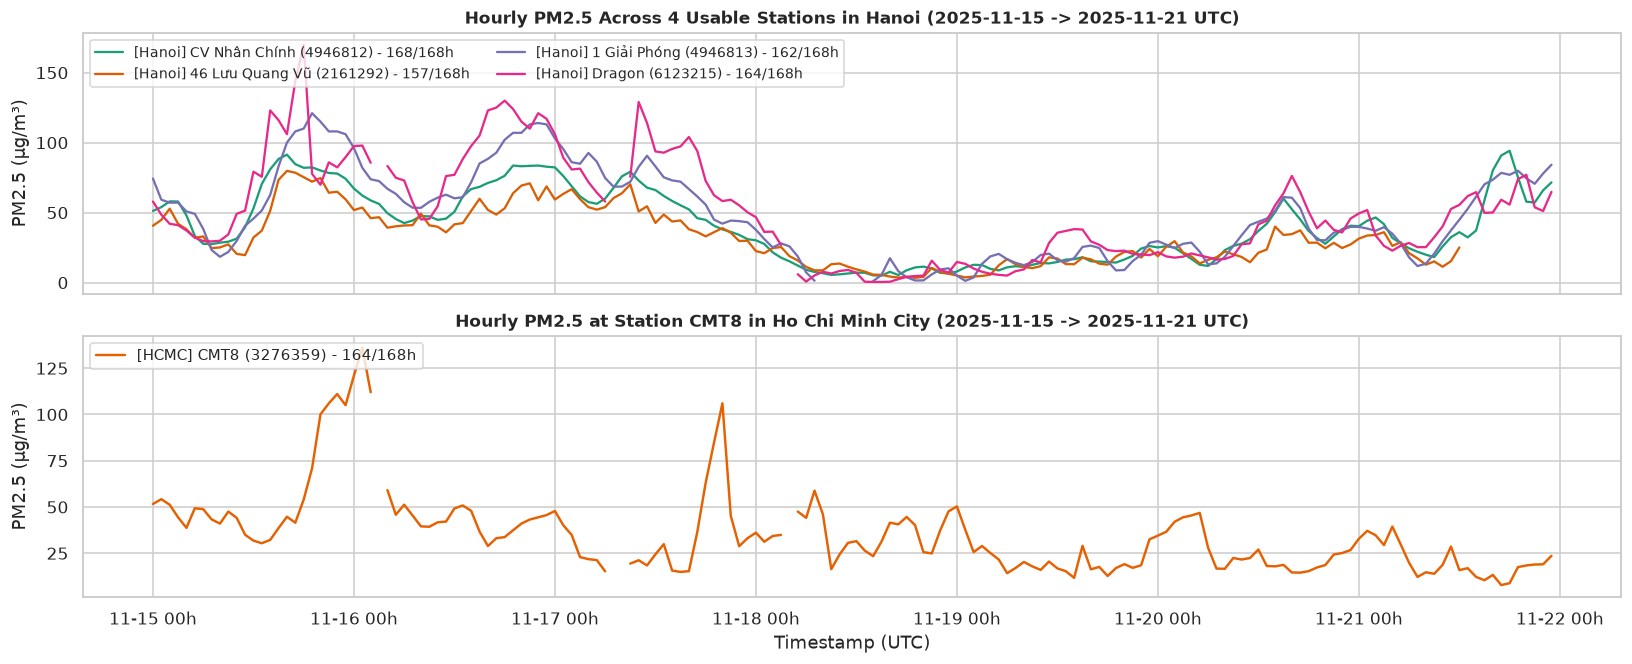

In [4]:
# Figure 2: 1-Week Hourly PM2.5 Time Series (preserving natural missing hours without interpolation)
fig, axes = plt.subplots(2, 1, figsize=(15, 6.2), sharex=True)

palette_map = {
    3276359: ("#e66101", "[HCMC] CMT8 (3276359) - 164/168h"),
    4946812: ("#1b9e77", "[Hanoi] CV Nhân Chính (4946812) - 168/168h"),
    2161292: ("#d95f02", "[Hanoi] 46 Lưu Quang Vũ (2161292) - 157/168h"),
    4946813: ("#7570b3", "[Hanoi] 1 Giải Phóng (4946813) - 162/168h"),
    6123215: ("#e7298a", "[Hanoi] Dragon (6123215) - 164/168h"),
}

for st_id in [4946812, 2161292, 4946813, 6123215]:
    color, label = palette_map[st_id]
    sub = (
        df_pm25[df_pm25["station_id"] == st_id]
        .set_index("event_time_dt")["pm25_ug_m3"]
        .reindex(full_sample_index)
    )
    axes[0].plot(sub.index, sub.values, label=label, color=color, linewidth=1.5)

axes[0].set_title("Hourly PM2.5 Across 4 Usable Stations in Hanoi (2025-11-15 -> 2025-11-21 UTC)")
axes[0].set_ylabel("PM2.5 (µg/m³)")
axes[0].legend(loc="upper left", ncol=2, fontsize=9)

color_hcm, label_hcm = palette_map[3276359]
sub_hcm = (
    df_pm25[df_pm25["station_id"] == 3276359]
    .set_index("event_time_dt")["pm25_ug_m3"]
    .reindex(full_sample_index)
)
axes[1].plot(sub_hcm.index, sub_hcm.values, label=label_hcm, color=color_hcm, linewidth=1.6)
axes[1].set_title("Hourly PM2.5 at Station CMT8 in Ho Chi Minh City (2025-11-15 -> 2025-11-21 UTC)")
axes[1].set_ylabel("PM2.5 (µg/m³)")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %Hh"))
axes[1].legend(loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.show()

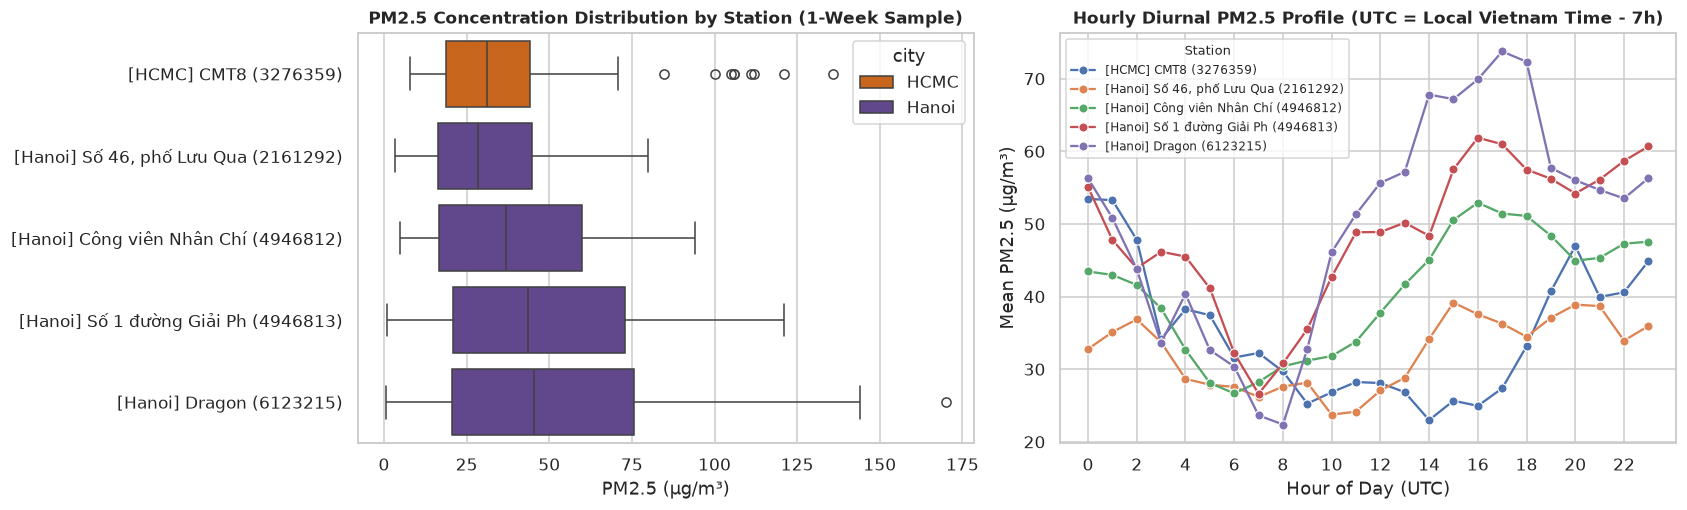

In [5]:
# Figure 3: PM2.5 Distribution by Station (Boxplot) & Diurnal Profile (UTC Hour)
df_merged["short_station"] = (
    "["
    + df_merged["city"]
    + "] "
    + df_merged["station_name"].str.slice(0, 18)
    + " ("
    + df_merged["station_id"].astype(str)
    + ")"
)
df_merged["hour_utc"] = df_merged["event_time_dt"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.8))

sns.boxplot(
    data=df_merged,
    y="short_station",
    x="pm25_ug_m3",
    hue="city",
    dodge=False,
    palette={"HCMC": "#e66101", "Hanoi": "#5e3c99"},
    ax=axes[0],
)
axes[0].set_title("PM2.5 Concentration Distribution by Station (1-Week Sample)")
axes[0].set_xlabel("PM2.5 (µg/m³)")
axes[0].set_ylabel("")

sns.lineplot(
    data=df_merged,
    x="hour_utc",
    y="pm25_ug_m3",
    hue="short_station",
    marker="o",
    errorbar=None,
    ax=axes[1],
)
axes[1].set_title("Hourly Diurnal PM2.5 Profile (UTC = Local Vietnam Time - 7h)")
axes[1].set_xlabel("Hour of Day (UTC)")
axes[1].set_ylabel("Mean PM2.5 (µg/m³)")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(title="Station", fontsize=8, title_fontsize=8.5, loc="upper left")

plt.tight_layout()
plt.show()

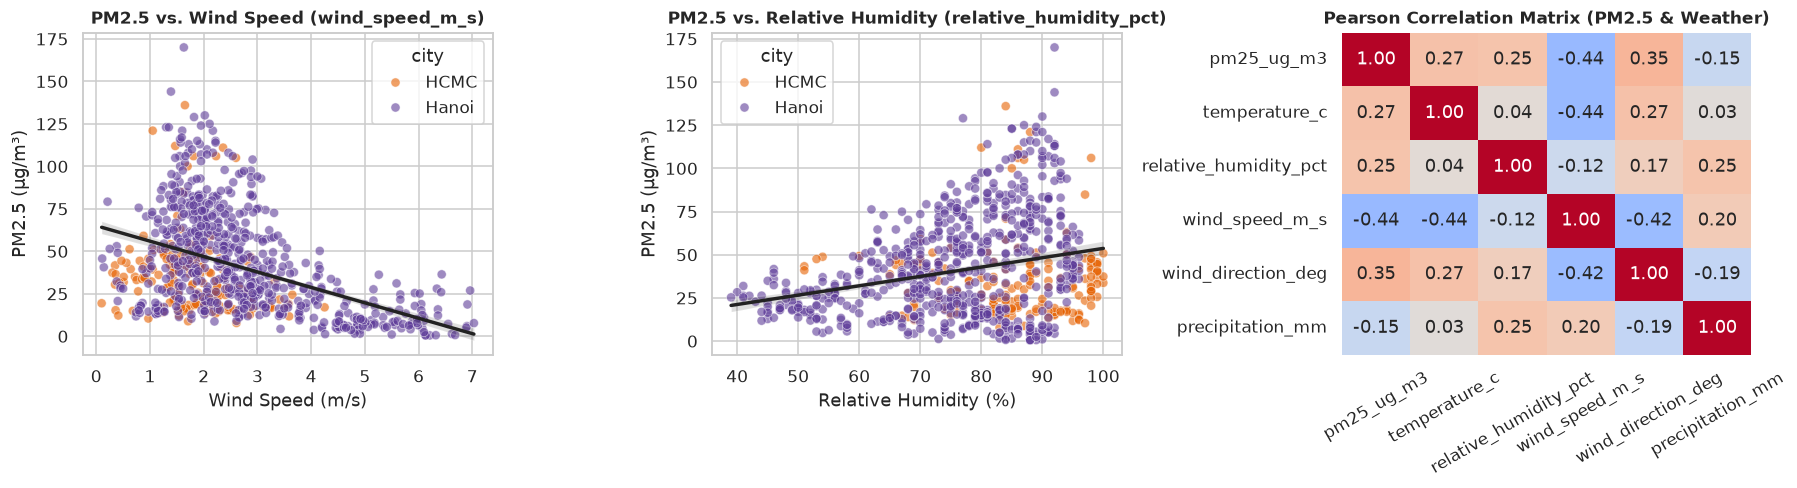

In [6]:
# Figure 4: Correlation Between PM2.5 and Open-Meteo Meteorological Variables
fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.6))

sns.scatterplot(
    data=df_merged,
    x="wind_speed_m_s",
    y="pm25_ug_m3",
    hue="city",
    palette={"HCMC": "#e66101", "Hanoi": "#5e3c99"},
    alpha=0.6,
    ax=axes[0],
)
sns.regplot(
    data=df_merged, x="wind_speed_m_s", y="pm25_ug_m3", scatter=False, color="#222222", ax=axes[0]
)
axes[0].set_title("PM2.5 vs. Wind Speed (wind_speed_m_s)")
axes[0].set_xlabel("Wind Speed (m/s)")
axes[0].set_ylabel("PM2.5 (µg/m³)")

sns.scatterplot(
    data=df_merged,
    x="relative_humidity_pct",
    y="pm25_ug_m3",
    hue="city",
    palette={"HCMC": "#e66101", "Hanoi": "#5e3c99"},
    alpha=0.6,
    ax=axes[1],
)
sns.regplot(
    data=df_merged,
    x="relative_humidity_pct",
    y="pm25_ug_m3",
    scatter=False,
    color="#222222",
    ax=axes[1],
)
axes[1].set_title("PM2.5 vs. Relative Humidity (relative_humidity_pct)")
axes[1].set_xlabel("Relative Humidity (%)")
axes[1].set_ylabel("PM2.5 (µg/m³)")

corr_cols = [
    "pm25_ug_m3",
    "temperature_c",
    "relative_humidity_pct",
    "wind_speed_m_s",
    "wind_direction_deg",
    "precipitation_mm",
]
corr_matrix = df_merged[corr_cols].corr()
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[2],
    cbar=False,
)
axes[2].set_title("Pearson Correlation Matrix (PM2.5 & Weather)")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 4. Conclusion

1. **Readiness for Live Demo & Streaming Pipeline:** The **5 active stations** (`3276359` in HCMC; `4946812`, `2161292`, `4946813`, `6123215` in Hanoi) paired with **Open-Meteo** (`100%` coverage, `100%` join match rate on `(station_id, event_time)` in full compliance with `docs/CONTRACTS.md`) are ready for real-time streaming ingestion and live demonstration.
2. **Readiness for Offline Drift & Adaptive Model Updating Experiments:** Because the cleanest Hanoi stations only began operating in mid/late 2025 (`4946812`, `4946813`, `6123215`) and the multi-year Hanoi station (`2161292`) suffers from `61` outages `>= 24h` (longest gap `859h`), offline multi-year drift experiments will use the **Beijing Multi-Site Air-Quality** benchmark dataset.